<a href="https://colab.research.google.com/github/itsabhi-21/Prognos/blob/main/notebooks/05a_tuning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Prognos: Remaining Useful Life Prediction for Turbofan Engines
## Notebook 5a: Hyperparameter Tuning with Optuna

**Goal:** Tune the GRU (best model in Notebook 4) systematically instead of using hand-picked values.

**Protocol**
- The objective is the validation RMSE on held-out training engines. The test set is never used during tuning.
- Search space: window length, hidden size, number of layers, dropout, learning rate, weight decay and batch size.
- Optuna's TPE sampler is used with 25 trials per subset. The default settings of Notebook 4 are re-evaluated with the same code for a fair before/after comparison.

## 1. Setup
Install Optuna, load the sliding windows from Notebook 3 and select the GPU.

In [1]:
!pip install -q optuna

import os, json, copy, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import GroupShuffleSplit
import optuna
from google.colab import drive

drive.mount('/content/drive')
PROC_DIR = '/content/drive/MyDrive/Prognos/processed'
SUBSETS = ['FD001', 'FD002', 'FD003', 'FD004']
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)

W = {fd: dict(np.load(f'{PROC_DIR}/windows_{fd}.npz')) for fd in SUBSETS}
optuna.logging.set_verbosity(optuna.logging.WARNING)

Mounted at /content/drive
device: cuda


## 2. Model and training function
The same GRU as in Notebook 4, now with configurable size and depth. The window length is varied by keeping only the last `win` cycles of each 30-cycle window.
Training uses early stopping on the validation engines (engine-wise split).

In [2]:
def set_seed(s=42):
    np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def rmse(y, p):
    return float(np.sqrt(np.mean((np.asarray(y) - np.asarray(p)) ** 2)))

class GRUNet(nn.Module):
    def __init__(self, n_feat, hidden, layers, dropout):
        super().__init__()
        self.rnn = nn.GRU(n_feat, hidden, layers, batch_first=True,
                          dropout=dropout if layers > 1 else 0.0)
        self.head = nn.Sequential(nn.Linear(hidden, 32), nn.ReLU(), nn.Linear(32, 1))
    def forward(self, x):
        out, _ = self.rnn(x)
        return self.head(out[:, -1]).squeeze(-1)

def predict(model, X):
    model.eval()
    outs = []
    with torch.no_grad():
        for i in range(0, len(X), 2048):
            outs.append(model(torch.tensor(X[i:i + 2048], dtype=torch.float32).to(device)).cpu())
    return torch.cat(outs).numpy()

def fit(params, X, y, units, seed=42, split_seed=42, epochs=30, patience=6):
    set_seed(seed)
    X = X[:, -params['win']:, :]
    tr_idx, va_idx = next(GroupShuffleSplit(1, test_size=0.2, random_state=split_seed).split(X, groups=units))
    dl = DataLoader(TensorDataset(torch.tensor(X[tr_idx], dtype=torch.float32),
                                  torch.tensor(y[tr_idx], dtype=torch.float32)),
                    batch_size=params['batch'], shuffle=True)
    model = GRUNet(X.shape[2], params['hidden'], params['layers'], params['dropout']).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=params['lr'], weight_decay=params['wd'])
    loss_fn = nn.MSELoss()
    best, best_state, bad = float('inf'), None, 0
    for ep in range(epochs):
        model.train()
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss_fn(model(xb), yb).backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
        v = rmse(y[va_idx], predict(model, X[va_idx]))
        if v < best - 1e-3:
            best, best_state, bad = v, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= patience:
                break
    model.load_state_dict(best_state)
    return model, best

DEFAULT = {'win': 30, 'hidden': 64, 'layers': 2, 'dropout': 0.2,
           'lr': 1e-3, 'wd': 0.0, 'batch': 256}   # settings used in Notebook 4

## 3. Search space and objective
Each trial samples one configuration, trains a GRU and returns the best validation RMSE (lower is better).

In [3]:
def make_objective(fd):
    d = W[fd]
    def objective(trial):
        params = {
            'win': trial.suggest_categorical('win', [15, 20, 30]),
            'hidden': trial.suggest_categorical('hidden', [32, 64, 128]),
            'layers': trial.suggest_int('layers', 1, 3),
            'dropout': trial.suggest_float('dropout', 0.0, 0.4),
            'lr': trial.suggest_float('lr', 1e-4, 3e-3, log=True),
            'wd': trial.suggest_float('wd', 1e-6, 1e-3, log=True),
            'batch': trial.suggest_categorical('batch', [128, 256, 512]),
        }
        _, val = fit(params, d['X_train'], d['y_train'], d['units_train'])
        return val
    return objective

## 4. Running the tuning
For each subset: evaluate the default configuration, run 25 Optuna trials, and save the best parameters to Drive after each subset (so progress survives a disconnected session).

In [4]:
N_TRIALS = 25
studies, summary = {}, []
best_params = {}

for fd in SUBSETS:
    d = W[fd]
    t0 = time.time()
    _, val_default = fit(DEFAULT, d['X_train'], d['y_train'], d['units_train'])

    study = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=42))
    study.optimize(make_objective(fd), n_trials=N_TRIALS)
    studies[fd] = study
    best_params[fd] = study.best_params

    summary.append({'subset': fd, 'val_rmse_default': round(val_default, 2),
                    'val_rmse_tuned': round(study.best_value, 2), **study.best_params})
    study.trials_dataframe().to_csv(f'{PROC_DIR}/optuna_trials_{fd}.csv', index=False)
    with open(f'{PROC_DIR}/best_params.json', 'w') as f:
        json.dump(best_params, f, indent=2)
    print(f'{fd} done in {(time.time() - t0) / 60:.1f} min | default {val_default:.2f} -> tuned {study.best_value:.2f}')

pd.DataFrame(summary).set_index('subset')

FD001 done in 3.4 min | default 11.33 -> tuned 11.14
FD002 done in 9.5 min | default 14.72 -> tuned 14.32
FD003 done in 5.4 min | default 10.14 -> tuned 10.53
FD004 done in 7.5 min | default 16.50 -> tuned 16.25


,val_rmse_default,val_rmse_tuned,win,hidden,layers,dropout,lr,wd,batch
subset,,,,,,,,,
FD001,11.33,11.14,30,64,2,0.243488,0.000325,0.000002,256
FD002,14.72,14.32,30,64,2,0.342812,0.000328,0.000002,256
FD003,10.14,10.53,30,64,1,0.002209,0.001602,0.000132,256
FD004,16.50,16.25,30,64,1,0.337044,0.002567,0.000048,512


## 5. Tuning progress
Each dot is one trial; the red line is the best validation RMSE found so far. A flattening line means the search has converged.

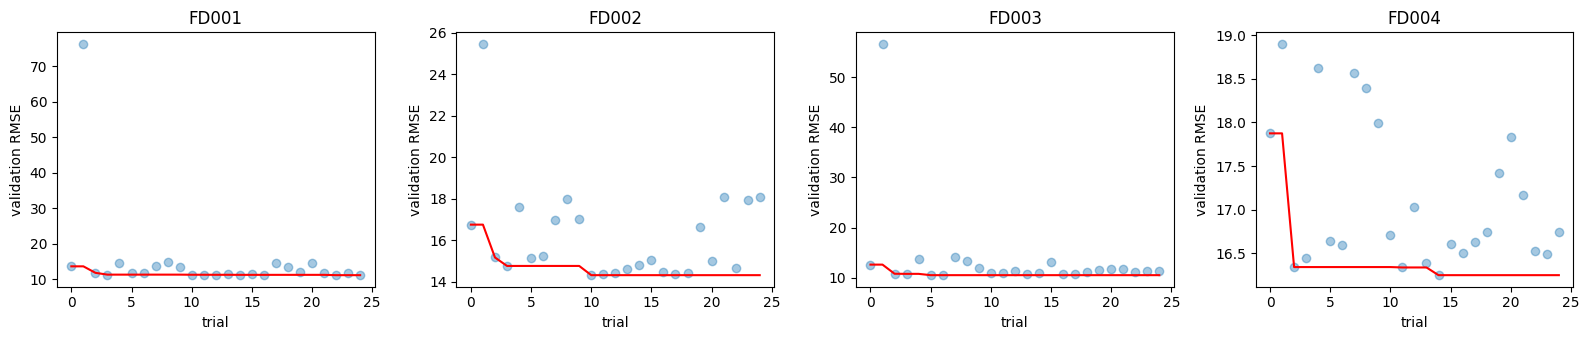

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, fd in zip(axes, SUBSETS):
    vals = [t.value for t in studies[fd].trials]
    ax.plot(vals, 'o', alpha=0.4)
    ax.plot(np.minimum.accumulate(vals), 'r-')
    ax.set_title(fd); ax.set_xlabel('trial'); ax.set_ylabel('validation RMSE')
plt.tight_layout(); plt.show()

## 6. Which hyperparameters mattered?
Optuna estimates the importance of each hyperparameter from the finished trials.

In [6]:
imp = pd.DataFrame({fd: optuna.importance.get_param_importances(studies[fd]) for fd in SUBSETS}).round(2)
imp

,FD001,FD002,FD003,FD004
layers,0.51,0.05,0.24,0.08
dropout,0.36,0.18,0.08,0.33
lr,0.05,0.53,0.52,0.37
hidden,0.04,0.00,0.05,0.05
wd,0.03,0.23,0.03,0.14
batch,0.01,0.00,0.08,0.03
win,0.01,0.00,0.00,0.00


## 7. Key findings

- **Tuning gave only small gains:** the best Optuna configuration lowered the validation RMSE from 11.33 to 11.14 (FD001), 14.72 to 14.32 (FD002) and 16.50 to 16.25 (FD004), about 1.5-2.7%. On FD003 the tuned configuration was worse than the default (10.53 vs 10.14), so the default is kept there. These differences are of the size of seed-to-seed noise; the hand-picked defaults of Notebook 4 were already close to a good setting.
- **The search converged quickly:** the best value was found within the first 3-15 of 25 trials and many configurations lie within about 0.5 RMSE of it, so the GRU is not very sensitive to these hyperparameters. A few random early trials with extreme settings reached validation RMSE of 55-76.
- **Most important hyperparameters:** the learning rate for FD002 (importance 0.53), FD003 (0.52) and FD004 (0.37), and the number of layers for FD001 (0.51). Hidden size (at most 0.05) and batch size (at most 0.08) hardly matter; a hidden size of 64 was selected on every subset.
- **Different optimum per subset:** FD001 and FD002 prefer two layers with a low learning rate (about 3e-4); FD003 and FD004 prefer a single layer with a higher learning rate (1.6e-3 and 2.6e-3).
- **Window length:** the longest allowed window (30 cycles) was chosen for every subset, so the search space boundary was reached. Longer windows (40-60 cycles, as used in some published work for FD002/FD004) were not tested.
- **Limitation:** dropout is applied only between GRU layers, so it has no effect for the single-layer models of FD003 and FD004, and its importance there is not meaningful.
- **Protocol:** Tuning used the validation RMSE on held-out training engines only; the test set was not touched.
- **Next step:** Notebook 5b trains both the default and the tuned configuration with five seeds and different engine splits, reports mean and standard deviation, compares with published results, and analyses the errors.